# DAY 36 : COMPLETE EXPLORATORY DATA ANALYSIS (EDA)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
sales_data = pd.read_excel("online_retail_II.xlsx")
sales_data.shape

(525461, 8)

In [6]:
sales_data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:
# inspect the columns
sales_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [8]:
sales_data.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [9]:
# missing value
sales_data.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [10]:
# To calculate missing-value percentages:
missing_pct = (
    sales_data.isnull().mean().mul(100).sort_values(ascending=False)
)

missing_pct

Customer ID    20.539488
Description     0.557225
Invoice         0.000000
StockCode       0.000000
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Country         0.000000
dtype: float64

In [12]:
# duplicate record
sales_data.duplicated().sum()

6865

In [14]:
# Investigate unusual transactions
sales_data.loc[
     (sales_data["Quantity"] <= 0) |
     (sales_data["Price"] <= 0),
     ["Invoice" ,"StockCode" , "Quantity" , "InvoiceDate" ,"Price"]
].head(10)

,Invoice,StockCode,Quantity,InvoiceDate,Price
178,C489449,22087,-12,2009-12-01 10:33:00,2.95
179,C489449,85206A,-6,2009-12-01 10:33:00,1.65
180,C489449,21895,-4,2009-12-01 10:33:00,4.25
181,C489449,21896,-6,2009-12-01 10:33:00,2.10
182,C489449,22083,-12,2009-12-01 10:33:00,2.95
183,C489449,21871,-12,2009-12-01 10:33:00,1.25
184,C489449,84946,-12,2009-12-01 10:33:00,1.25
185,C489449,84970S,-24,2009-12-01 10:33:00,0.85
186,C489449,22090,-12,2009-12-01 10:33:00,2.95
196,C489459,90200A,-3,2009-12-01 10:44:00,4.25


In [15]:
# quantify unusual transactions
# Count non-positive quantities
non_positive_quantity = (sales_data["Quantity"] <= 0).sum()

# Count non-positive prices
non_positive_price = (sales_data["Price"] <= 0).sum()

# Count cancellation invoices
cancellation_invoices = (
    sales_data["Invoice"].astype(str).str.startswith("C").sum()
)

print("Non-positive quantities:", non_positive_quantity)
print("Non-positive prices:", non_positive_price)
print("Cancellation invoice rows:", cancellation_invoices)

Non-positive quantities: 12326
Non-positive prices: 3690
Cancellation invoice rows: 10206


In [16]:
# imvestigate cancellation record
# Create a cancellation indicator
sales_data["Is_Cancelled"] = (
    sales_data["Invoice"]
    .astype(str)
    .str.startswith("C")
)

# Compare cancellation status with quantity sign
pd.crosstab(
    sales_data["Is_Cancelled"],
    sales_data["Quantity"] <= 0,
    margins=True
)


Quantity,False,True,All
Is_Cancelled,,,
False,513134,2121,515255
True,1,10205,10206
All,513135,12326,525461


In [17]:
# non-cancellation Exception
# Investigate non-cancellation rows with non-positive quantities
sales_data.loc[
    (~sales_data["Is_Cancelled"]) &
    (sales_data["Quantity"] <= 0),
    ["Invoice", "StockCode", "Description",
     "Quantity", "InvoiceDate", "Price", "Country"]
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,United Kingdom


In [ ]:
sales_data_clean = sales_data.copy()

# Remove exact duplicate rows
sales_data_clean = sales_data_clean.drop_duplicates()

# Remove rows without a product description
sales_data_clean = sales_data_clean.dropna(subset=["Description"])

# Verify the cleaning
print("Cleaned shape:", sales_data_clean.shape)
print("Duplicate rows:", sales_data_clean.duplicated().sum())
print("\nMissing values:")
print(sales_data_clean.isnull().sum())


Cleaned shape: (515668, 9)
Duplicate rows: 0

Missing values:
Invoice              0
StockCode            0
Description          0
Quantity             0
InvoiceDate          0
Price                0
Customer ID     104905
Country              0
Is_Cancelled         0
dtype: int64


In [20]:
sales_data_clean["Sales"]= (
     sales_data_clean["Quantity"] * sales_data_clean["Price"]
)
sales_data_clean[["Quantity" , "Price" , "Sales"]].describe()

,Quantity,Price,Sales
count,515668.000000,515668.000000,515668.000000
mean,10.617719,4.742955,18.433906
std,98.548503,147.507035,161.831991
min,-9360.000000,-53594.360000,-53594.360000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.100000,10.080000
75%,10.000000,4.210000,17.700000
max,19152.000000,25111.090000,25111.090000


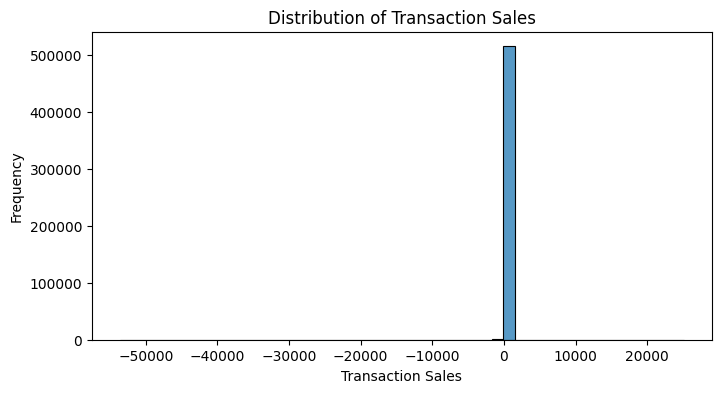

In [21]:
# now visualize the sales distribution

plt.figure(figsize=(8, 4))

sns.histplot(
    data=sales_data_clean,
    x="Sales",
    bins=50
)

plt.title("Distribution of Transaction Sales")
plt.xlabel("Transaction Sales")
plt.ylabel("Frequency")
plt.show()


### Improve the visualisation

In [22]:

# Examine the sales distribution at selected percentiles
sales_data_clean["Sales"].quantile(
    [0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
)


0.01     -9.90
0.25      3.75
0.50     10.08
0.75     17.70
0.95     60.00
0.99    183.60
Name: Sales, dtype: float64

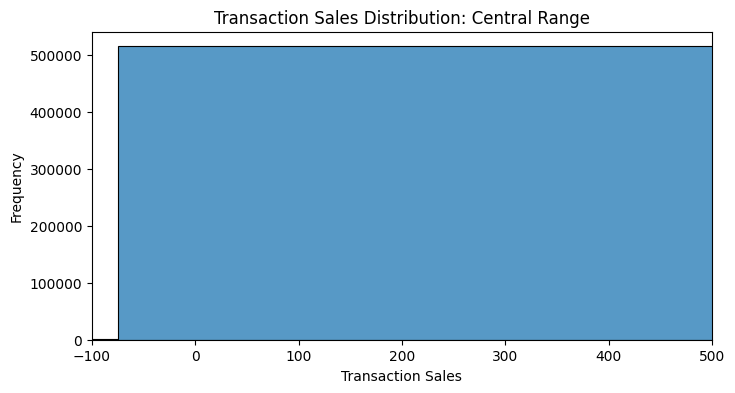

In [23]:

plt.figure(figsize=(8, 4))

sns.histplot(
    data=sales_data_clean,
    x="Sales",
    bins=50
)

plt.xlim(-100, 500)
plt.title("Transaction Sales Distribution: Central Range")
plt.xlabel("Transaction Sales")
plt.ylabel("Frequency")
plt.show()


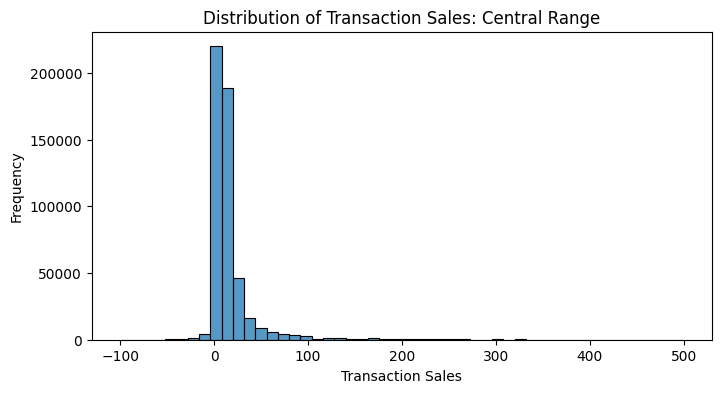

In [24]:

# Keep only the central range for visualization
sales_central = sales_data_clean.loc[
    sales_data_clean["Sales"].between(-100, 500),
    "Sales"
]

plt.figure(figsize=(8, 4))

sns.histplot(
    x=sales_central,
    bins=50
)

plt.title("Distribution of Transaction Sales: Central Range")
plt.xlabel("Transaction Sales")
plt.ylabel("Frequency")
plt.show()
